In [38]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.sparse import hstack
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student_exam_outcomes.csv")

In [3]:
df.head()

,study_hours_per_day,attendance_percent,assignment_completion_percent,sleep_hours,tutoring,previous_exam_score,passed
0,4.2,89.4,66,6.5,Yes,32.7,1
1,0.2,66.1,73,7.0,Yes,69.8,0
2,5.5,84.8,37,7.4,No,35.6,1
3,5.6,75.7,46,6.7,No,46.6,1
4,0.7,96.7,80,6.1,Yes,81.9,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   study_hours_per_day            400 non-null    float64
 1   attendance_percent             400 non-null    float64
 2   assignment_completion_percent  400 non-null    int64  
 3   sleep_hours                    400 non-null    float64
 4   tutoring                       400 non-null    str    
 5   previous_exam_score            400 non-null    float64
 6   passed                         400 non-null    int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 22.0 KB


In [5]:
X = df.drop("passed", axis=1)

In [6]:
categorical_col = X.select_dtypes(exclude="number").columns
numerical_col = X.select_dtypes(include="number").columns

In [8]:
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [9]:
X_scaled = scaler.fit_transform(df[numerical_col])
X_encoded = encoder.fit_transform(df[categorical_col])

In [10]:
X_processed = np.hstack([X_scaled, X_encoded])

In [11]:
model = KMeans(
    n_clusters=2,
    init= "k-means++",
    n_init=10,
    random_state=42
)

In [12]:
labels = model.fit_predict(X_processed)

In [13]:
df["clusters"] = labels

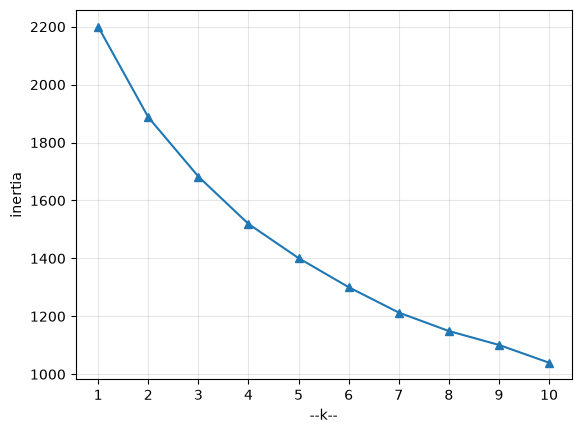

In [14]:
wcss = []

for k in range(1, 11):
    k_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    k_model.fit_predict(X_processed)
    wcss.append(k_model.inertia_)

plt.plot(
    range(1, 11),
    wcss,
    marker="^"
)
plt.xlabel("--k--"); plt.ylabel("inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

For value of k: 2, Score: 0.1369
For value of k: 3, Score: 0.1324
For value of k: 4, Score: 0.1371
For value of k: 5, Score: 0.1405
For value of k: 6, Score: 0.1433
For value of k: 7, Score: 0.1466
For value of k: 8, Score: 0.1472
For value of k: 9, Score: 0.1506
For value of k: 10, Score: 0.1575


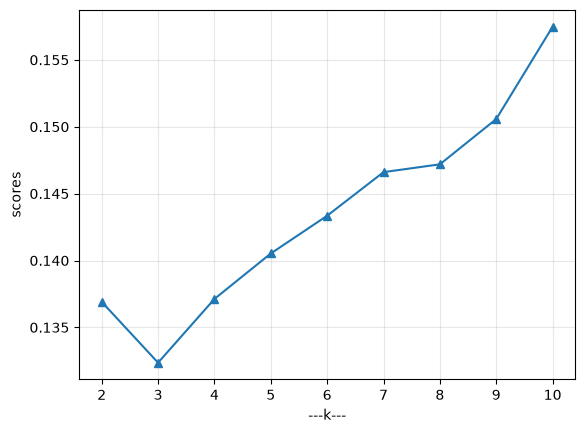

In [15]:
silhouette_scores = []

for k in range(2, 11):
    t_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    label = t_model.fit_predict(X_processed)
    score = silhouette_score(X_processed, label)
    silhouette_scores.append(score)

    print(f"For value of k: {k}, Score: {score:.4f}")

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="^"
)
plt.xlabel("---k---"); plt.ylabel("scores")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()

In [16]:
KModel_4 = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)
label_4 = KModel_4.fit_predict(X_processed)

df["cluster_4"] = label_4

In [17]:
KModel_10 = KMeans(
    n_clusters=10,
    init="k-means++",
    n_init=10,
    random_state=42
)
label_10 = KModel_10.fit_predict(X_processed)

df["cluster_10"] = label_10

In [18]:
print(X_processed.shape)

(400, 7)


In [19]:
for k, model, label_n in [
    (4, KModel_4, label_4),
    (10, KModel_10, label_10)
]:
    print(f"\n For clusters k value = {k}")

    print(f"Silhouette_Score: {silhouette_score(X_processed, label_n)}")

    print(f"davies_bouldin_Score: {davies_bouldin_score(X_processed, label_n)}")

    print(f"calinski_harabasz_Score: {calinski_harabasz_score(X_processed, label_n)}")


 For clusters k value = 4
Silhouette_Score: 0.13712661737936183
davies_bouldin_Score: 1.8889375679809137
calinski_harabasz_Score: 59.16825231847916

 For clusters k value = 10
Silhouette_Score: 0.15747974483990776
davies_bouldin_Score: 1.504800103201973
calinski_harabasz_Score: 48.3413339824726


In [23]:
features = ['study_hours_per_day', 'attendance_percent',
       'assignment_completion_percent', 'sleep_hours',
       'previous_exam_score'] 

In [24]:
print("for k = ", 2)

print(df.groupby("cluster_4")[features].mean().round(2))

for k =  2
           study_hours_per_day  attendance_percent  \
cluster_4                                            
0                         1.82               71.85   
1                         5.18               70.04   
2                         5.92               69.56   
3                         1.87               75.07   

           assignment_completion_percent  sleep_hours  previous_exam_score  
cluster_4                                                                   
0                                  65.40         7.61                76.00  
1                                  40.87         6.53                73.56  
2                                  71.52         7.37                50.60  
3                                  66.32         6.23                41.96  


In [25]:
print("for k = ", 10)

print(df.groupby("cluster_10")[features].mean().round(2))

for k =  10
            study_hours_per_day  attendance_percent  \
cluster_10                                            
0                          2.20               81.01   
1                          5.65               58.57   
2                          3.84               53.90   
3                          1.65               59.58   
4                          1.17               86.01   
5                          5.64               84.42   
6                          5.24               84.17   
7                          2.35               76.30   
8                          6.76               71.42   
9                          4.50               61.43   

            assignment_completion_percent  sleep_hours  previous_exam_score  
cluster_10                                                                   
0                                   84.36         6.46                41.08  
1                                   39.67         6.28                75.80  
2              

In [27]:
print(df["cluster_4"].value_counts().sort_index())

cluster_4
0     96
1     99
2    118
3     87
Name: count, dtype: int64


In [28]:
print(df["cluster_10"].value_counts().sort_index())

cluster_10
0    45
1    42
2    50
3    41
4    42
5    43
6    38
7    30
8    36
9    33
Name: count, dtype: int64


In [46]:
seeds = [0, 10, 21, 42, 100]

for k in range(1, 11):
    all_labels = []
    for seed in seeds:
        s_model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=seed
        )

        label = s_model.fit_predict(X_processed)
        all_labels.append(label)

    ari_scores = []
    for i in range(1, len(all_labels)):
        for j in range(i+1, len(all_labels)):
            adj_score = adjusted_rand_score(all_labels[i], all_labels[j])
            ari_scores.append(adj_score)

    print(f"Average stability for {k}: {np.mean(ari_scores).round(4)}")
    print(f"Minimum stability for {k}: {np.min(ari_scores).round(4)}\n")
        

Average stability for 1: 1.0
Minimum stability for 1: 1.0

Average stability for 2: 0.5069
Minimum stability for 2: 0.0789

Average stability for 3: 0.5089
Minimum stability for 3: 0.2806

Average stability for 4: 0.5297
Minimum stability for 4: 0.3913

Average stability for 5: 0.4416
Minimum stability for 5: 0.3328

Average stability for 6: 0.4067
Minimum stability for 6: 0.2964

Average stability for 7: 0.4363
Minimum stability for 7: 0.3338

Average stability for 8: 0.4904
Minimum stability for 8: 0.4225

Average stability for 9: 0.5466
Minimum stability for 9: 0.4488

Average stability for 10: 0.4897
Minimum stability for 10: 0.3842



Text(0.5, 1.0, 'for k = 10')

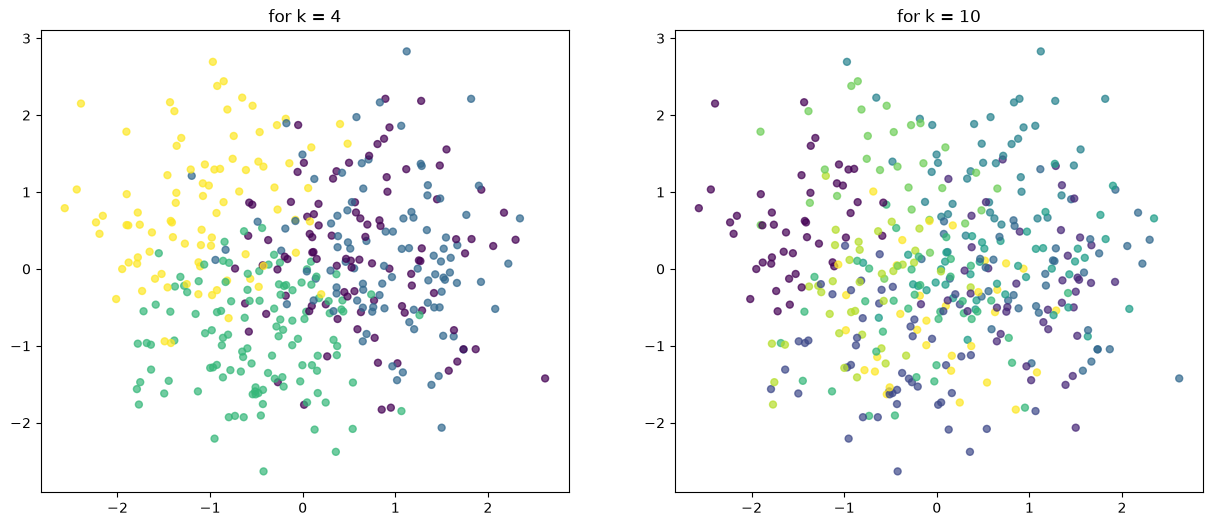

In [45]:
pca = PCA(n_components=2)

x_pca = pca.fit_transform(X_processed)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c= label_4,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[0].set_title("for k = 4")

# axes[0].scatter(
#     x_pca[:, 0],
#     x_pca[:, 1],
#     c= labels,
#     cmap="viridis",
#     s=25,
#     alpha=0.7
# )
# axes[0].set_title("for k = 2")

axes[1].scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c= label_10,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[1].set_title("for k = 10")